# Chapter 1 — What Is Machine Learning?

*From examples to predictions, and how to set up your workshop*

## 1.1 Learning objectives

After working through this chapter you will be able to:

1. explain what it means for a program to *learn from data*, and tell the main kinds of learning problems apart (regression, classification, clustering, reinforcement learning);
2. represent a dataset as a matrix $\mathbf{X}$ and a vector $\mathbf{y}$, and read their shapes;
3. formulate learning as the minimization of a loss, and compute a baseline to compare against;
4. derive the normal equations of least squares, interpret them geometrically, and verify them in code;
5. explain overfitting and underfitting, and why a model must be evaluated on data it has not seen;
6. run a complete workflow *split → preprocess → fit → evaluate* with scikit-learn;
7. set up the environment, run the notebooks, and build and publish this book as a static website (see the [Setup Guide](ch01_setup_guide.md)).

**Prerequisites.** Vectors, matrices, dot products, the gradient. Nothing else.

**How to read this chapter.** The first sections build intuition; Sections 1.6–1.8 are the technical core; the exercises at the end are the best way to check your understanding. Every code cell can be executed, and changed, in your own copy of the notebook.

### Setting up this notebook

The next two cells print the versions of the libraries used to produce the outputs you see in this page, and define the plotting style and the random seed used throughout the book. If you run the notebook yourself and your versions differ slightly, small numerical differences in the printed results are normal.

In [1]:
import platform
from importlib.metadata import version

print("Python", platform.python_version())
for pkg in ["numpy", "scipy", "pandas", "matplotlib", "seaborn", "scikit-learn"]:
    print(f"{pkg:<14}{version(pkg)}")

Python 3.15.2
numpy         2.5.5
scipy         1.18.1
pandas        3.1.1
matplotlib    3.11.2
seaborn       0.13.2
scikit-learn  1.9.1


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42  # fixed seed: random operations give the same result every time

# Plotting style used throughout the book.
# Colors from the Okabe-Ito palette, designed to stay distinguishable
# for readers with color-vision deficiencies.
BLUE, ORANGE, GREEN = "#0072B2", "#E69F00", "#009E73"
VERMILION, SKY, PURPLE = "#D55E00", "#56B4E9", "#CC79A7"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (6.4, 4.0),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

## 1.2 Learning from examples

Most programs you have written follow *rules that a human wrote down*: "if the input is negative, return an error", "sort the list with this procedure". This works when we can describe the rules. It fails for tasks such as recognizing a handwritten digit, flagging a spam message, or estimating how a patient's condition will evolve: nobody can write down the rules, but we can easily collect **examples**.

**Machine learning** replaces "write the rules" with "show examples and let an algorithm find the rules". A classical way to say this, due to Tom Mitchell, is the following. A program *learns* from experience $E$ with respect to a task $T$ and a performance measure $P$ if its performance on $T$, as measured by $P$, improves with experience $E$.

| | Spam filter | Diagnosis support |
|---|---|---|
| Task $T$ | label a message as spam or not | label a tumor as benign or malignant |
| Experience $E$ | messages already labeled by users | patient records with a confirmed diagnosis |
| Performance $P$ | fraction of new messages labeled correctly | fraction of new patients labeled correctly |

:::{admonition} Key idea
:class: tip
Learning means improving performance on **new** data by using past data. A program that only memorizes its examples has not learned anything useful.
:::

### Kinds of learning

The kind of experience we have decides the kind of problem:

| Paradigm | What the data looks like | Typical goal | Where in this book |
|---|---|---|---|
| **Supervised learning** | inputs $\mathbf{x}$ *with* the desired outputs $y$ | predict $y$ for a new $\mathbf{x}$ | Parts I–II and most of Part IV |
| **Unsupervised learning** | inputs $\mathbf{x}$ only | discover structure: groups, directions of variation | Part III, autoencoders (Chapter 20) |
| **Reinforcement learning** | an agent acting in an environment and receiving rewards | choose actions that maximize the total reward | Chapter 22 |

Supervised learning has two main flavors, depending on the output:

- **regression**: $y$ is a real number (the price of a house, the progression of a disease);
- **classification**: $y$ is one of a finite number of classes (spam / not spam, the species of a flower, a digit from 0 to 9).

(Mixed settings, such as *semi-supervised* learning, where only some examples have labels, are discussed in Chapter 12.)

## 1.3 Anatomy of a supervised learning problem

Every supervised method in this book is built from the same five ingredients.

1. **Data.** A *training set* $S = \{(\mathbf{x}_i, y_i)\}_{i=1}^{n}$ of $n$ examples. Each $\mathbf{x}_i \in \mathbb{R}^d$ lists $d$ measurable properties (the *features*), and $y_i$ is the *target* (or *label*).
2. **Model.** A family of candidate functions $f(\mathbf{x}; \mathbf{w})$ that map an input to a prediction $\hat{y}$. The vector $\mathbf{w}$ collects the *parameters* that the algorithm will choose.
3. **Loss.** A function $\ell(y, \hat{y}) \ge 0$ that measures how wrong a prediction is.
4. **Learning algorithm.** A procedure that chooses $\mathbf{w}$ so that the average loss on the training set is small: this is an *optimization* problem.
5. **Evaluation.** A way to estimate how well the chosen model will do on **new** data.

A word on vocabulary: the same objects go by many names. Rows are called *samples*, *examples*, or *observations*; columns are *features*, *predictors*, or *covariates*; $y$ is the *target*, *label*, or *response*. We also distinguish **parameters** (learned by the algorithm from the data, such as $\mathbf{w}$) from **hyperparameters** (chosen by you before training, such as the number of neighbors in k-NN or the strength of a regularizer). Chapter 5 is devoted to choosing hyperparameters well.

## 1.4 Data as matrices

Here is where linear algebra enters. Stack the $n$ input vectors as rows of a matrix:

$$
\mathbf{X} =
\begin{pmatrix}
\mathbf{x}_1^\top \\ \vdots \\ \mathbf{x}_n^\top
\end{pmatrix}
\in \mathbb{R}^{n \times d},
\qquad
\mathbf{y} =
\begin{pmatrix}
y_1 \\ \vdots \\ y_n
\end{pmatrix}
\in \mathbb{R}^{n}.
$$

Each *row* of $\mathbf{X}$ is one sample, i.e. a point in $\mathbb{R}^d$. Each *column* is one feature measured on all samples. This is exactly the convention of NumPy, pandas, and scikit-learn: `X` has shape `(n_samples, n_features)`.

Our first dataset is the famous **Iris** data set, collected by the botanist Edgar Anderson and made known to statisticians by R. A. Fisher (1936). It contains 150 flowers from 3 species of iris, each described by 4 measurements in centimeters. It is bundled with scikit-learn, so no download is needed.

In [3]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)          # as_frame=True gives pandas objects
X_iris = iris.data.to_numpy()            # the data matrix X, shape (n, d)
y_iris = iris.target.to_numpy()          # the targets y, integers 0, 1, 2

print("X shape:", X_iris.shape, "-> n =", X_iris.shape[0], "samples, d =", X_iris.shape[1], "features")
print("y shape:", y_iris.shape)
print("features:", list(iris.data.columns))
print("classes :", iris.target_names.tolist())

X shape: (150, 4) -> n = 150 samples, d = 4 features
y shape: (150,)
features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
classes : ['setosa', 'versicolor', 'virginica']


In [4]:
iris.data.head()   # the first five rows of X

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Because each sample is a point of $\mathbb{R}^4$, we can use geometry. The **Euclidean distance** between two samples is

$$
\lVert \mathbf{x}_i - \mathbf{x}_j \rVert_2 = \sqrt{\sum_{k=1}^{d} (x_{ik} - x_{jk})^2},
$$

and flowers of the same species should be closer to each other than flowers of different species. This simple idea, "similar inputs have similar outputs", is the basis of many algorithms.

### Worked example 1.1 — a distance by hand

Take sample 0 and sample 1 of the data set (both *setosa*), and sample 100 (*virginica*). Their coordinates, in the order (sepal length, sepal width, petal length, petal width), are

$$
\mathbf{x}_0 = (5.1,\ 3.5,\ 1.4,\ 0.2), \quad
\mathbf{x}_1 = (4.9,\ 3.0,\ 1.4,\ 0.2), \quad
\mathbf{x}_{100} = (6.3,\ 3.3,\ 6.0,\ 2.5).
$$

*Step 1.* $\mathbf{x}_0 - \mathbf{x}_1 = (0.2,\ 0.5,\ 0,\ 0)$, so
$\lVert \mathbf{x}_0 - \mathbf{x}_1 \rVert_2 = \sqrt{0.04 + 0.25} = \sqrt{0.29} \approx 0.539$.

*Step 2.* $\mathbf{x}_0 - \mathbf{x}_{100} = (-1.2,\ 0.2,\ -4.6,\ -2.3)$, so
$\lVert \mathbf{x}_0 - \mathbf{x}_{100} \rVert_2 = \sqrt{1.44 + 0.04 + 21.16 + 5.29} = \sqrt{27.93} \approx 5.285$.

The two *setosa* flowers are about ten times closer to each other than a *setosa* is to a *virginica*. Let us check with NumPy.

In [5]:
x0, x1, x100 = X_iris[0], X_iris[1], X_iris[100]
print("x0   =", x0)
print("x1   =", x1)
print("x100 =", x100)
print("distance(x0, x1)   =", round(float(np.linalg.norm(x0 - x1)), 4))
print("distance(x0, x100) =", round(float(np.linalg.norm(x0 - x100)), 4))

x0   = [5.1 3.5 1.4 0.2]
x1   = [4.9 3.  1.4 0.2]
x100 = [6.3 3.3 6.  2.5]
distance(x0, x1)   = 0.5385
distance(x0, x100) = 5.2849


### Figure 1.1 — the Iris data as points in feature space

We cannot draw $\mathbb{R}^4$, but we can look at two features at a time. The code below is self-contained: you can copy it into a script and run it as it is. Species are encoded by color *and* by marker shape, so the figure stays readable in black and white.

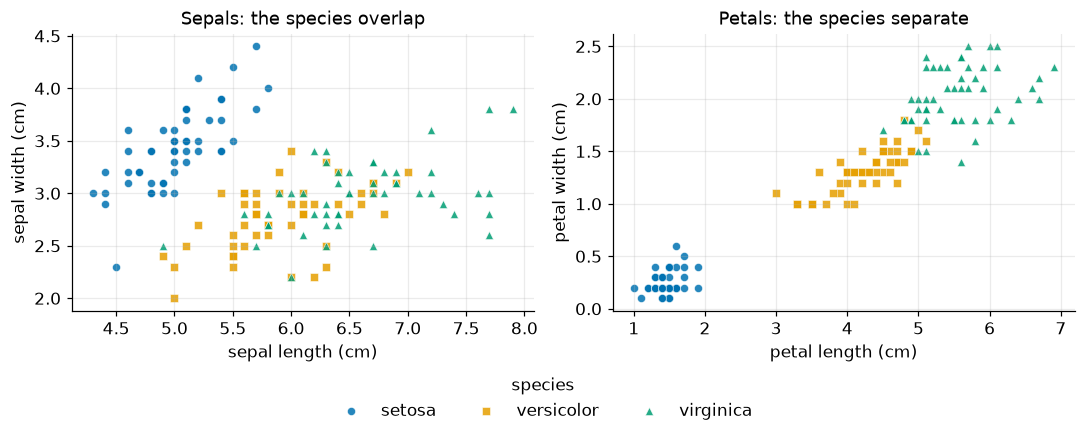

In [6]:
# Figure 1.1 — two views of the Iris data set
# (the figure code lives in a function, so that it does not overwrite
#  variables of the notebook such as X, y or w)
def figure_1_1():
    import matplotlib.pyplot as plt
    from sklearn.datasets import load_iris

    iris = load_iris(as_frame=True)
    data, target = iris.data, iris.target
    colors = [BLUE, ORANGE, GREEN]
    markers = ["o", "s", "^"]

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    views = [("sepal length (cm)", "sepal width (cm)"), ("petal length (cm)", "petal width (cm)")]
    for ax, (fx, fy) in zip(axes, views):
        for k, name in enumerate(iris.target_names):
            mask = target == k
            ax.scatter(data.loc[mask, fx], data.loc[mask, fy], s=28, c=colors[k],
                       marker=markers[k], alpha=0.85, edgecolor="white", linewidth=0.4, label=name)
        ax.set_xlabel(fx)
        ax.set_ylabel(fy)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, title="species", loc="lower center", ncol=3, frameon=False)
    axes[0].set_title("Sepals: the species overlap")
    axes[1].set_title("Petals: the species separate")
    fig.tight_layout(rect=(0, 0.12, 1, 1))
    plt.show()

figure_1_1()

The petal measurements separate the three species much better than the sepal ones. A learning algorithm has to discover such facts from the data, usually in dimensions where we cannot draw a picture.

### Our very first learner: the nearest class mean

To make the vocabulary *model, fit, predict* concrete, here is a learner that needs only a mean.

- **Fit.** For each class $c$, compute the mean $\boldsymbol{\mu}_c$ of the training samples of that class. The parameters of the model are these class means.
- **Predict.** Given a new $\mathbf{x}$, return the class whose mean is closest: $\hat{y} = \operatorname{argmin}_c \lVert \mathbf{x} - \boldsymbol{\mu}_c \rVert_2$.

We train it on part of the data and test it on the rest. (Why we split the data is explained in Section 1.7; for the moment, accept that the *test* samples play the role of "new" flowers.)

In [7]:
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(
    X_iris, y_iris, test_size=0.3, stratify=y_iris, random_state=SEED
)
print("training samples:", X_tr.shape[0], "| test samples:", X_te.shape[0])

# FIT: one mean vector per class -> a 3 x 4 matrix of parameters
class_means = np.vstack([X_tr[y_tr == c].mean(axis=0) for c in range(3)])
print("class means (rows = classes):")
print(class_means.round(3))

# PREDICT: distance from every test sample to every class mean, then argmin
diffs = X_te[:, None, :] - class_means[None, :, :]      # shape (n_test, 3, 4)
distances = np.linalg.norm(diffs, axis=2)               # shape (n_test, 3)
y_pred = distances.argmin(axis=1)

print("test accuracy:", round(float(np.mean(y_pred == y_te)), 3))

training samples: 105 | test samples: 45
class means (rows = classes):
[[4.989 3.426 1.486 0.24 ]
 [5.949 2.731 4.237 1.309]
 [6.683 3.009 5.631 2.069]]
test accuracy: 0.911


Roughly nine flowers out of ten are labeled correctly by a model made of twelve numbers. This is a very simple learner, yet it already has every ingredient of Section 1.3.

:::{admonition} Try it
:class: note
Change `test_size` or `random_state` in the split above and re-run the two cells. How much does the accuracy move? We will come back to this variability in Chapter 5.
:::

## 1.5 Learning as optimization: losses and baselines

How do we say that a model is "good"? We choose a **loss function** $\ell(y, \hat{y})$ that scores one prediction, and we average it over the training set. For regression, the most common choices are

$$
\ell_{\text{sq}}(y, \hat{y}) = (y - \hat{y})^2 \quad \text{(squared loss)},
\qquad
\ell_{\text{abs}}(y, \hat{y}) = \lvert y - \hat{y} \rvert \quad \text{(absolute loss)},
$$

and for classification the **0–1 loss**, $\ell_{0\text{-}1}(y, \hat{y}) = \mathbb{I}[y \neq \hat{y}]$, which counts mistakes. The average loss on the training set is the **empirical risk**

$$
\hat{R}_S(f) = \frac{1}{n} \sum_{i=1}^{n} \ell\bigl(y_i,\, f(\mathbf{x}_i)\bigr).
$$

With the squared loss, $\hat{R}_S(f)$ is the **mean squared error** (MSE). *Learning* then means: among the functions of the model family, find the one with the smallest empirical risk,

$$
\hat{\mathbf{w}} = \operatorname*{argmin}_{\mathbf{w}} \ \hat{R}_S\bigl(f(\cdot\,; \mathbf{w})\bigr).
$$

This principle is called **empirical risk minimization**; Chapter 3 studies when and why it works.

### The simplest model: a constant

Before building anything clever, ask: how well can we do while *ignoring the input*? Let the model be a constant, $f(\mathbf{x}) = c$. With the squared loss we want

$$
\min_{c} \ \frac{1}{n}\sum_{i=1}^{n} (y_i - c)^2 .
$$

The derivative with respect to $c$ is $-\frac{2}{n}\sum_i (y_i - c)$. Setting it to zero gives $c = \frac{1}{n}\sum_i y_i = \bar{y}$: **the best constant predictor under the squared loss is the sample mean**, and its MSE is the (population) variance of $y$.

This *baseline* is more useful than it looks. Any serious model must beat it, otherwise the inputs are not helping. The **coefficient of determination** measures the improvement over this baseline:

$$
R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}.
$$

$R^2 = 0$ means "no better than the mean", $R^2 = 1$ means perfect predictions (on the data used to compute it).

### The data: the Diabetes data set

We use the **Diabetes** data set bundled with scikit-learn (Efron, Hastie, Johnstone and Tibshirani, 2004): 442 patients, ten baseline measurements (age, sex, body mass index `bmi`, average blood pressure `bp`, and six blood serum measurements `s1`–`s6`), and a quantitative measure of disease progression one year later, which is our target $y$. By default scikit-learn returns the features already centered and rescaled; we ask for the original units with `scaled=False`, so that the numbers are easier to interpret.

In [8]:
from sklearn.datasets import load_diabetes

diab = load_diabetes(as_frame=True, scaled=False)
X_diab, y_diab = diab.data, diab.target
print("shape of X:", X_diab.shape, "| shape of y:", y_diab.shape)
X_diab.describe().loc[["mean", "std", "min", "max"]].round(2).T

shape of X: (442, 10) | shape of y: (442,)


,mean,std,min,max
age,48.52,13.11,19.00,79.00
sex,1.47,0.50,1.00,2.00
bmi,26.38,4.42,18.00,42.20
bp,94.65,13.83,62.00,133.00
s1,189.14,34.61,97.00,301.00
s2,115.44,30.41,41.60,242.40
s3,49.79,12.93,22.00,99.00
s4,4.07,1.29,2.00,9.09
s5,4.64,0.52,3.26,6.11
s6,91.26,11.50,58.00,124.00


In [9]:
# The best constant predictor and its MSE (the baseline)
y = y_diab.to_numpy()
y_mean = y.mean()
mse_baseline = np.mean((y - y_mean) ** 2)

print(f"mean of y            : {y_mean:.2f}")
print(f"MSE of the baseline  : {mse_baseline:.2f}")
print(f"variance of y (ddof=0): {np.var(y):.2f}   <- the same number, as the theory says")

# Check numerically that no other constant does better
candidates = np.linspace(y.min(), y.max(), 2001)
mse_curve = np.array([np.mean((y - c) ** 2) for c in candidates])
print(f"best constant on a grid: {candidates[mse_curve.argmin()]:.1f}")

mean of y            : 152.13
MSE of the baseline  : 5929.88
variance of y (ddof=0): 5929.88   <- the same number, as the theory says
best constant on a grid: 152.1


## 1.6 Our first real learner: least squares

A constant ignores the inputs. The next step up is a **linear model**:

$$
f(\mathbf{x}; \mathbf{w}, b) = \mathbf{w}^\top \mathbf{x} + b = w_1 x_1 + \dots + w_d x_d + b .
$$

The *intercept* $b$ can be absorbed into the weights by adding a constant feature equal to 1 to every sample. From now on, in this section, $\mathbf{X} \in \mathbb{R}^{n\times p}$ denotes the data matrix *including* a leading column of ones (so $p = d + 1$) and $\mathbf{w} \in \mathbb{R}^p$ contains $b$ as its first entry. All predictions at once are then $\hat{\mathbf{y}} = \mathbf{X}\mathbf{w}$.

### Derivation of the normal equations

With the squared loss, learning means minimizing

$$
L(\mathbf{w}) = \lVert \mathbf{y} - \mathbf{X}\mathbf{w} \rVert_2^2
= (\mathbf{y} - \mathbf{X}\mathbf{w})^\top (\mathbf{y} - \mathbf{X}\mathbf{w}).
$$

(This is $n$ times the MSE; the factor $n$ does not change the minimizer.)

*Step 1: expand.* Using $(\mathbf{X}\mathbf{w})^\top = \mathbf{w}^\top\mathbf{X}^\top$ and the fact that the scalar $\mathbf{y}^\top \mathbf{X}\mathbf{w}$ equals its own transpose $\mathbf{w}^\top \mathbf{X}^\top \mathbf{y}$:

$$
L(\mathbf{w}) = \mathbf{y}^\top\mathbf{y} - 2\,\mathbf{w}^\top \mathbf{X}^\top \mathbf{y} + \mathbf{w}^\top \mathbf{X}^\top \mathbf{X}\,\mathbf{w}.
$$

*Step 2: differentiate.* For a vector $\mathbf{a}$ and a symmetric matrix $\mathbf{A}$ we have $\nabla_{\mathbf{w}}\,(\mathbf{a}^\top \mathbf{w}) = \mathbf{a}$ and $\nabla_{\mathbf{w}}\,(\mathbf{w}^\top \mathbf{A}\mathbf{w}) = 2\mathbf{A}\mathbf{w}$. Hence

$$
\nabla_{\mathbf{w}} L(\mathbf{w}) = -2\,\mathbf{X}^\top \mathbf{y} + 2\,\mathbf{X}^\top \mathbf{X}\,\mathbf{w}.
$$

*Step 3: set the gradient to zero.* We obtain the **normal equations**

$$
\boxed{\ \mathbf{X}^\top \mathbf{X}\,\mathbf{w} = \mathbf{X}^\top \mathbf{y}\ }
$$

If the columns of $\mathbf{X}$ are linearly independent, $\mathbf{X}^\top\mathbf{X}$ is invertible and $\hat{\mathbf{w}} = (\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top\mathbf{y}$.

*Why this is a minimum.* The Hessian of $L$ is $2\mathbf{X}^\top\mathbf{X}$, which is positive semidefinite because $\mathbf{v}^\top \mathbf{X}^\top\mathbf{X}\mathbf{v} = \lVert \mathbf{X}\mathbf{v} \rVert_2^2 \ge 0$. So $L$ is convex and any solution of the normal equations is a global minimizer.

### The geometric picture

The vectors $\mathbf{X}\mathbf{w}$, as $\mathbf{w}$ varies, fill the **column space** of $\mathbf{X}$, a subspace of $\mathbb{R}^n$. Least squares looks for the point of this subspace *closest* to $\mathbf{y}$, which is the **orthogonal projection** of $\mathbf{y}$ onto it. Writing the residual as $\mathbf{r} = \mathbf{y} - \mathbf{X}\hat{\mathbf{w}}$, the normal equations say exactly

$$
\mathbf{X}^\top \mathbf{r} = \mathbf{0},
$$

that is, the residual is **orthogonal to every column** of $\mathbf{X}$ (hence the name "normal"). The prediction vector is $\hat{\mathbf{y}} = \mathbf{H}\mathbf{y}$ with the *projection* ("hat") matrix $\mathbf{H} = \mathbf{X}(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top$. Since the first column of $\mathbf{X}$ is all ones, the first normal equation reads $\sum_i r_i = 0$: with an intercept, **the residuals always sum to zero**.

:::{admonition} Key idea
:class: tip
Linear least squares is nothing more than an orthogonal projection. The "learning algorithm" is a linear-algebra computation, and the quality of the fit is the length of the part of $\mathbf{y}$ that the columns of $\mathbf{X}$ cannot reach.
:::

### Worked example 1.2 — three points by hand

Fit a line $y = w_0 + w_1 x$ to the three points $(0, 1)$, $(1, 3)$, $(2, 4)$. Here

$$
\mathbf{X} = \begin{pmatrix} 1 & 0 \\ 1 & 1 \\ 1 & 2 \end{pmatrix},
\qquad
\mathbf{y} = \begin{pmatrix} 1 \\ 3 \\ 4 \end{pmatrix}.
$$

*Step 1: the normal equations.*

$$
\mathbf{X}^\top\mathbf{X} = \begin{pmatrix} 3 & 3 \\ 3 & 5 \end{pmatrix},
\qquad
\mathbf{X}^\top\mathbf{y} = \begin{pmatrix} 8 \\ 11 \end{pmatrix}.
$$

*Step 2: solve.* $\det(\mathbf{X}^\top\mathbf{X}) = 15 - 9 = 6$, so

$$
\hat{\mathbf{w}} = \frac{1}{6}\begin{pmatrix} 5 & -3 \\ -3 & 3 \end{pmatrix}\begin{pmatrix} 8 \\ 11 \end{pmatrix}
= \frac{1}{6}\begin{pmatrix} 7 \\ 9 \end{pmatrix}
= \begin{pmatrix} 7/6 \\ 3/2 \end{pmatrix}.
$$

The fitted line is $\hat{y} = \tfrac{7}{6} + \tfrac{3}{2}x$.

*Step 3: predictions and residuals.* $\hat{\mathbf{y}} = \bigl(\tfrac{7}{6},\ \tfrac{8}{3},\ \tfrac{25}{6}\bigr)^\top$ and $\mathbf{r} = \mathbf{y} - \hat{\mathbf{y}} = \bigl(-\tfrac16,\ \tfrac13,\ -\tfrac16\bigr)^\top$.

*Step 4: check orthogonality.* The sum of the residuals is $-\tfrac16 + \tfrac13 - \tfrac16 = 0$, and $\mathbf{r}\cdot(0,1,2) = 0 + \tfrac13 - \tfrac13 = 0$. Both columns of $\mathbf{X}$ are orthogonal to $\mathbf{r}$, as the theory predicts.

*Step 5: error and $R^2$.* $\sum_i r_i^2 = \tfrac{1}{36} + \tfrac{4}{36} + \tfrac{1}{36} = \tfrac16$, so the MSE is $\tfrac{1}{18} \approx 0.056$. The baseline has $\sum_i (y_i - \bar{y})^2 = \tfrac{14}{3}$ (with $\bar y = \tfrac83$), hence $R^2 = 1 - \tfrac{1/6}{14/3} = \tfrac{27}{28} \approx 0.964$.

Now the same computation in Python.

In [10]:
X_toy = np.array([[1.0, 0.0],
                  [1.0, 1.0],
                  [1.0, 2.0]])
y_toy = np.array([1.0, 3.0, 4.0])

A = X_toy.T @ X_toy
b = X_toy.T @ y_toy
print("X^T X =\n", A)
print("X^T y =", b)

w_toy = np.linalg.solve(A, b)                   # solves the normal equations
print("w     =", w_toy, "  (expected 7/6 and 3/2:", 7 / 6, 3 / 2, ")")

y_hat = X_toy @ w_toy
r = y_toy - y_hat
print("y_hat =", y_hat)
print("r     =", r)
print("X^T r =", np.round(X_toy.T @ r, 12), "  <- orthogonality of the residual")
print("MSE   =", np.mean(r ** 2), "  (expected 1/18 =", 1 / 18, ")")

sst = np.sum((y_toy - y_toy.mean()) ** 2)
print("R^2   =", 1 - np.sum(r ** 2) / sst, "  (expected 27/28 =", 27 / 28, ")")

X^T X =
 [[3. 3.]
 [3. 5.]]
X^T y = [ 8. 11.]
w     = [1.16666667 1.5       ]   (expected 7/6 and 3/2: 1.1666666666666667 1.5 )
y_hat = [1.16666667 2.66666667 4.16666667]
r     = [-0.16666667  0.33333333 -0.16666667]
X^T r = [-0. -0.]   <- orthogonality of the residual
MSE   = 0.05555555555555553   (expected 1/18 = 0.05555555555555555 )
R^2   = 0.9642857142857143   (expected 27/28 = 0.9642857142857143 )


### Figure 1.2 — least squares as a projection

The three samples of the toy problem live in $\mathbb{R}^3$. The two columns of $\mathbf{X}$ span a plane (the column space). The vector $\mathbf{y}$ is *not* on the plane; its projection $\hat{\mathbf{y}}$ is the closest point of the plane, and the residual $\mathbf{r}$ is perpendicular to it. For the picture we keep the matrix $\mathbf{X}$ of Worked example 1.2 but use the targets $\mathbf{y} = (3, 1, 4)^\top$, whose fit is worse: this makes the residual long enough to be seen. The right panel shows the same picture looking *along* the plane, so that the plane appears as a line and the right angle between the residual and the plane becomes visible.

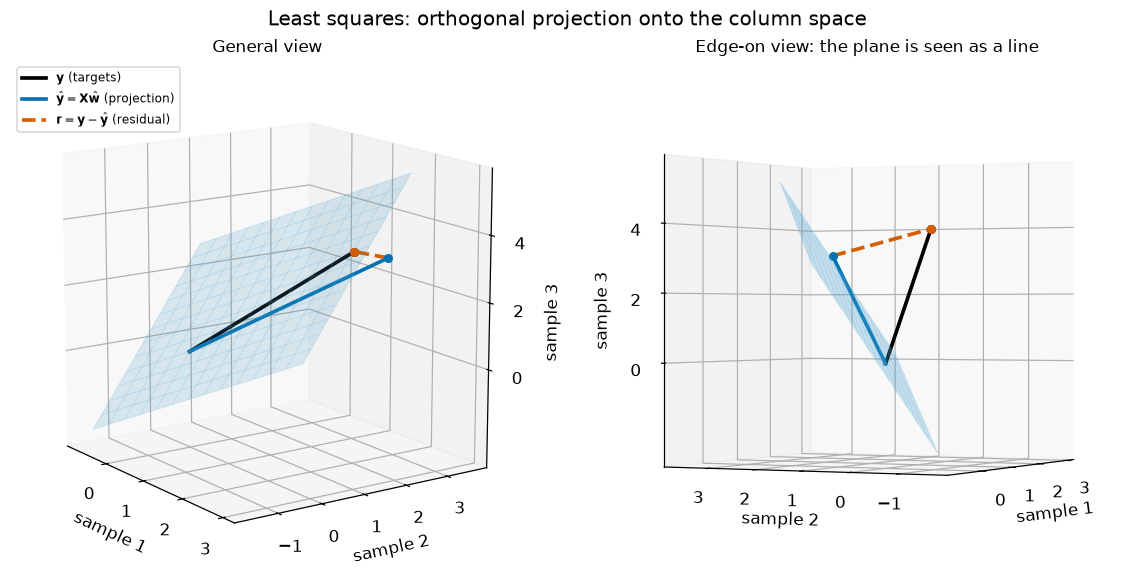

In [11]:
# Figure 1.2 — geometry of least squares for a small example
def figure_1_2():
    import numpy as np
    import matplotlib.pyplot as plt

    # same matrix X as in Worked example 1.2, but with targets y = (3, 1, 4):
    # the fit is worse, so the residual is long enough to be seen clearly
    X = np.array([[1.0, 0.0], [1.0, 1.0], [1.0, 2.0]])
    y = np.array([3.0, 1.0, 4.0])
    w = np.linalg.solve(X.T @ X, X.T @ y)
    y_hat = X @ w

    # a direction perpendicular to the plane: the cross product of the two columns of X.
    # Looking at the plane "edge-on" means looking along a direction orthogonal to it.
    normal = np.cross(X[:, 0], X[:, 1])                   # = (1, -2, 1)
    azim_edge_on = np.degrees(np.arctan2(-normal[0], normal[1]))   # azimuth whose view direction is in the plane
    # view direction for (elev=0, azim): (cos azim, sin azim, 0). We need it orthogonal to `normal`.
    assert abs(np.dot([np.cos(np.radians(azim_edge_on)), np.sin(np.radians(azim_edge_on)), 0], normal)) < 1e-9

    fig = plt.figure(figsize=(11, 5.4))
    views = [(14, -35, "General view"), (0, azim_edge_on, "Edge-on view: the plane is seen as a line")]
    for k, (elev, azim, title) in enumerate(views, start=1):
        ax = fig.add_subplot(1, 2, k, projection="3d")

        # the plane spanned by the two columns of X (the column space)
        s, t = np.meshgrid(np.linspace(-0.8, 1.8, 14), np.linspace(-0.8, 1.8, 14))
        plane = s[..., None] * X[:, 0] + t[..., None] * X[:, 1]
        ax.plot_surface(plane[..., 0], plane[..., 1], plane[..., 2], alpha=0.18, color=SKY, linewidth=0)
        ax.plot_wireframe(plane[..., 0], plane[..., 1], plane[..., 2], color=SKY, alpha=0.35, linewidth=0.4)

        origin = np.zeros(3)
        for start, end, color, label, ls in [
            (origin, y, "black", r"$\mathbf{y}$ (targets)", "-"),
            (origin, y_hat, BLUE, r"$\hat{\mathbf{y}} = \mathbf{X}\hat{\mathbf{w}}$ (projection)", "-"),
            (y_hat, y, VERMILION, r"$\mathbf{r} = \mathbf{y} - \hat{\mathbf{y}}$ (residual)", "--"),
        ]:
            ax.plot(*zip(start, end), color=color, linewidth=2.4, linestyle=ls, label=label)
            ax.scatter(*end, color=color, s=24)

        ax.set_xlabel("sample 1")
        ax.set_ylabel("sample 2")
        ax.set_zlabel("sample 3")
        ax.set_title(title, fontsize=11)
        ax.set_xticks([0, 1, 2, 3])
        ax.set_yticks([-1, 0, 1, 2, 3])
        ax.set_zticks([0, 2, 4])
        ax.set_box_aspect((1, 1, 1))
        ax.view_init(elev=elev, azim=azim)
        if k == 1:
            ax.legend(loc="upper left", fontsize=8)
    fig.suptitle("Least squares: orthogonal projection onto the column space", y=0.98)
    fig.tight_layout()
    plt.show()

figure_1_2()

### Least squares on real data: predicting disease progression from BMI

We now fit a line to the Diabetes data, using a single feature, the body mass index. We compute the solution in three ways: with the normal equations, with `np.linalg.lstsq`, and with scikit-learn's `LinearRegression`. They should agree.

:::{admonition} Pitfall
:class: warning
Writing `np.linalg.inv(X.T @ X) @ X.T @ y` is mathematically correct but numerically fragile: the matrix $\mathbf{X}^\top\mathbf{X}$ can be nearly singular, and inverting it amplifies rounding errors. Solve the linear system (`np.linalg.solve`) or, better, use `np.linalg.lstsq`, which relies on the SVD of $\mathbf{X}$ and also copes with rank-deficient matrices. We will understand why in Chapter 13. Exercise 1.10 shows a failure case.
:::

In [12]:
from sklearn.linear_model import LinearRegression

bmi = X_diab["bmi"].to_numpy()
A_bmi = np.column_stack([np.ones_like(bmi), bmi])          # add the column of ones

w_normal = np.linalg.solve(A_bmi.T @ A_bmi, A_bmi.T @ y)   # 1) normal equations
w_lstsq = np.linalg.lstsq(A_bmi, y, rcond=None)[0]         # 2) SVD-based solver
sk = LinearRegression().fit(bmi.reshape(-1, 1), y)         # 3) scikit-learn

print("normal equations  :", w_normal.round(4))
print("np.linalg.lstsq   :", w_lstsq.round(4))
print("scikit-learn      :", np.array([sk.intercept_, sk.coef_[0]]).round(4))
print("all three agree   :", np.allclose(w_normal, w_lstsq) and np.allclose(w_normal, [sk.intercept_, sk.coef_[0]]))

y_hat_bmi = A_bmi @ w_lstsq
mse_bmi = np.mean((y - y_hat_bmi) ** 2)
r2_bmi = 1 - np.sum((y - y_hat_bmi) ** 2) / np.sum((y - y.mean()) ** 2)
print(f"\nMSE: {mse_bmi:.1f}  (baseline: {mse_baseline:.1f})")
print(f"R^2: {r2_bmi:.3f}")
print(f"sum of residuals: {np.sum(y - y_hat_bmi):.2e}   <- zero, as shown in the theory")

normal equations  : [-117.7734   10.2331]
np.linalg.lstsq   : [-117.7734   10.2331]
scikit-learn      : [-117.7734   10.2331]
all three agree   : True

MSE: 3890.5  (baseline: 5929.9)
R^2: 0.344
sum of residuals: 3.01e-11   <- zero, as shown in the theory


The slope says that, on this data set, one extra unit of BMI goes with about ten extra units of disease progression. The fit explains roughly a third of the variance of $y$ (the exact $R^2$ is printed above): clearly better than the baseline, but far from perfect.

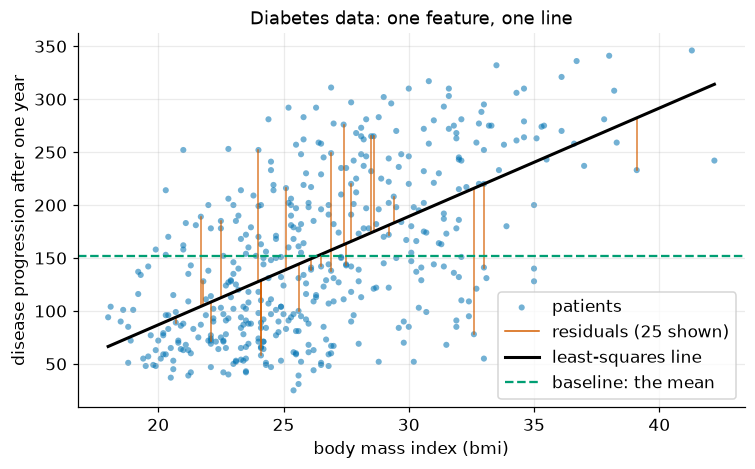

In [13]:
# Figure 1.3 — the least-squares line and its residuals
def figure_1_3():
    import numpy as np
    import matplotlib.pyplot as plt
    from sklearn.datasets import load_diabetes

    d = load_diabetes(as_frame=True, scaled=False)
    x, t = d.data["bmi"].to_numpy(), d.target.to_numpy()
    A = np.column_stack([np.ones_like(x), x])
    w = np.linalg.lstsq(A, t, rcond=None)[0]

    fig, ax = plt.subplots(figsize=(7, 4.4))
    ax.scatter(x, t, s=16, color=BLUE, alpha=0.55, edgecolor="none", label="patients")

    # residuals of a few randomly chosen points, to make the "errors" visible
    rng = np.random.default_rng(SEED)
    for i in rng.choice(len(x), size=25, replace=False):
        ax.plot([x[i], x[i]], [t[i], w[0] + w[1] * x[i]], color=VERMILION, linewidth=1, alpha=0.8)
    ax.plot([], [], color=VERMILION, linewidth=1, label="residuals (25 shown)")

    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, w[0] + w[1] * xs, color="black", linewidth=2, label="least-squares line")
    ax.axhline(t.mean(), color=GREEN, linestyle="--", linewidth=1.5, label="baseline: the mean")
    ax.set_xlabel("body mass index (bmi)")
    ax.set_ylabel("disease progression after one year")
    ax.set_title("Diabetes data: one feature, one line")
    ax.legend()
    fig.tight_layout()
    plt.show()

figure_1_3()

### Using all ten features

Nothing changes in the mathematics when $d$ grows: $\mathbf{X}$ just gets more columns. (In the single-feature case we fit a line in the plane; with ten features we fit a *hyperplane* in $\mathbb{R}^{11}$, which we cannot draw but can compute.)

In [14]:
A_all = np.column_stack([np.ones(len(y)), X_diab.to_numpy()])      # shape (442, 11)
w_all = np.linalg.lstsq(A_all, y, rcond=None)[0]
y_hat_all = A_all @ w_all

r2_all = 1 - np.sum((y - y_hat_all) ** 2) / np.sum((y - y.mean()) ** 2)
print("shape of the design matrix:", A_all.shape)
print(f"R^2 with all 10 features (on the training data): {r2_all:.3f}   |   with bmi alone: {r2_bmi:.3f}")

pd.Series(w_all, index=["intercept"] + list(X_diab.columns)).round(3)

shape of the design matrix: (442, 11)
R^2 with all 10 features (on the training data): 0.518   |   with bmi alone: 0.344


intercept   -334.567
age           -0.036
sex          -22.860
bmi            5.603
bp             1.117
s1            -1.090
s2             0.746
s3             0.372
s4             6.534
s5            68.483
s6             0.280
dtype: float64

The $R^2$ rose, as it must: adding columns can only enlarge the column space and bring the projection closer to $\mathbf{y}$. But the $R^2$ computed *on the data used to fit the model* is an optimistic number. The next section explains why, and what to do about it.

## 1.7 Generalization: why we need a test set

What we really care about is not the loss on the training samples, but the loss on **future** samples drawn from the same source. Call $\mathcal{D}$ the (unknown) distribution that generates the data. The quantity of interest is the **expected risk**

$$
R(f) = \mathbb{E}_{(\mathbf{x}, y) \sim \mathcal{D}}\bigl[\ell\bigl(y, f(\mathbf{x})\bigr)\bigr],
$$

which we cannot compute because $\mathcal{D}$ is unknown. The empirical risk $\hat{R}_S(f)$ on the training set is a *biased* estimate of it, because $f$ was chosen precisely to make $\hat{R}_S(f)$ small. The standard remedy is to keep some samples aside:

- the **training set** is used to fit the model;
- the **test set** is never used for fitting, only to estimate $R(f)$ at the very end.

### Overfitting and underfitting

A model that is too rigid cannot capture the pattern in the data: **underfitting**. A model that is too flexible also adapts to the random fluctuations of the training sample, which will not repeat on new data: **overfitting**. Flexibility can be controlled in many ways; here we use the simplest one, the **degree of a polynomial**. We fit $f(x) = w_0 + w_1 x + \dots + w_m x^m$ to the BMI/progression data. This is still *linear* least squares: the "features" are $1, x, x^2, \dots, x^m$, and the normal equations are the same as before.

To make the effect visible we train on only **30** patients and test on the remaining 412. (With few training examples, flexible models overfit sooner; this is a general phenomenon.) The right panel repeats the experiment on 300 different random splits and reports the *median* error, which is more reliable than a single split.

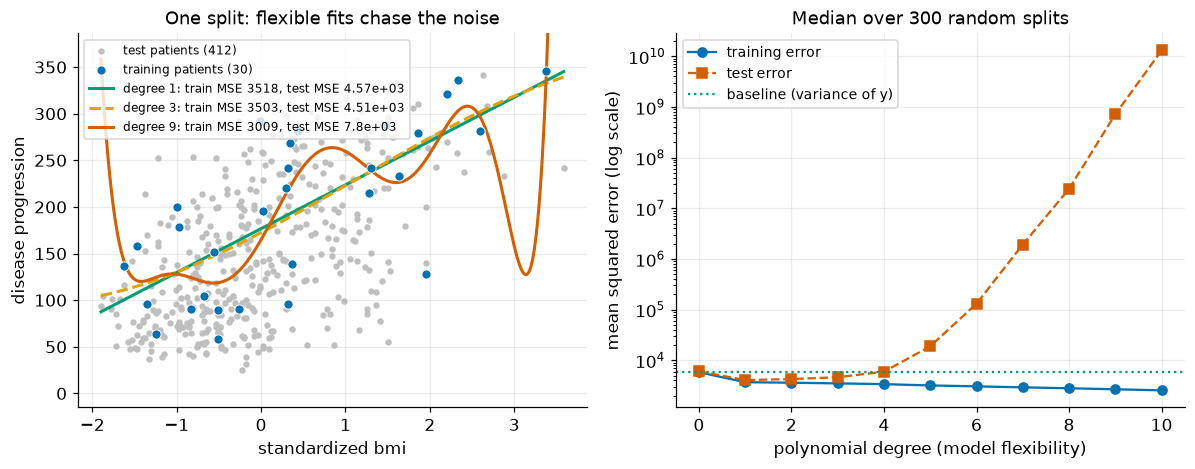

Degree with the smallest median test error: 1
Training error never increases with the degree (nested models, same data): True


In [15]:
# Figure 1.4 — fits of increasing flexibility, and training vs. test error
import numpy as np
from numpy.polynomial import polynomial as P
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

N_TRAIN, MAX_DEG = 30, 10

def fit_and_score(z_tr, y_tr, z_te, y_te, degree):
    """Least squares on the features 1, z, ..., z^degree; returns the coefficients and the two MSEs."""
    coef = P.polyfit(z_tr, y_tr, degree)
    mse = lambda zz, yy: np.mean((yy - P.polyval(zz, coef)) ** 2)
    return coef, mse(z_tr, y_tr), mse(z_te, y_te)

def figure_1_4():
    import matplotlib.pyplot as plt

    d = load_diabetes(as_frame=True, scaled=False)
    bmi, target = d.data["bmi"].to_numpy(), d.target.to_numpy()
    z = (bmi - bmi.mean()) / bmi.std()          # standardize the feature for numerical stability

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

    # Left: one particular split, three polynomial degrees
    z_tr, z_te, y_tr, y_te = train_test_split(z, target, train_size=N_TRAIN, random_state=3)
    axes[0].scatter(z_te, y_te, s=10, color="0.75", label="test patients (412)")
    axes[0].scatter(z_tr, y_tr, s=36, color=BLUE, edgecolor="white", linewidth=0.6, zorder=3,
                    label=f"training patients ({N_TRAIN})")
    grid = np.linspace(z.min(), z.max(), 300)
    for degree, color, style in [(1, GREEN, "-"), (3, ORANGE, "--"), (9, VERMILION, "-")]:
        coef, mse_tr, mse_te = fit_and_score(z_tr, y_tr, z_te, y_te, degree)
        axes[0].plot(grid, P.polyval(grid, coef), color=color, linestyle=style, linewidth=2,
                     label=f"degree {degree}: train MSE {mse_tr:.0f}, test MSE {mse_te:.3g}")
    axes[0].set_ylim(target.min() - 40, target.max() + 40)
    axes[0].set_xlabel("standardized bmi")
    axes[0].set_ylabel("disease progression")
    axes[0].set_title("One split: flexible fits chase the noise")
    axes[0].legend(fontsize=8, loc="upper left")

    # Right: median errors over many random splits
    errs = np.zeros((300, MAX_DEG + 1, 2))
    for s in range(300):
        z_tr, z_te, y_tr, y_te = train_test_split(z, target, train_size=N_TRAIN, random_state=s)
        for degree in range(MAX_DEG + 1):
            _, errs[s, degree, 0], errs[s, degree, 1] = fit_and_score(z_tr, y_tr, z_te, y_te, degree)
    med = np.median(errs, axis=0)
    degrees = np.arange(MAX_DEG + 1)
    axes[1].plot(degrees, med[:, 0], "o-", color=BLUE, label="training error")
    axes[1].plot(degrees, med[:, 1], "s--", color=VERMILION, label="test error")
    axes[1].axhline(np.var(target), color=GREEN, linestyle=":", linewidth=1.5, label="baseline (variance of y)")
    axes[1].set_yscale("log")
    axes[1].set_xlabel("polynomial degree (model flexibility)")
    axes[1].set_ylabel("mean squared error (log scale)")
    axes[1].set_title("Median over 300 random splits")
    axes[1].legend(fontsize=9)
    fig.tight_layout()
    plt.show()
    return med

med = figure_1_4()
best = int(np.argmin(med[:, 1]))
print(f"Degree with the smallest median test error: {best}")
print("Training error never increases with the degree (nested models, same data):",
      bool(np.all(np.diff(med[:, 0]) <= 1e-9)))

Read the right panel from left to right.

- **Training error** goes down all the way: a more flexible model can always fit the training sample at least as well (the models are nested). On its own it would tell us to pick the most complex model.
- **Test error** is high at degree 0 (**underfitting**: the constant ignores the input; it is the baseline), is lowest at a low degree, and then explodes (**overfitting**): the high-degree polynomials oscillate wildly between and beyond the training points, as the left panel shows.

The gap between the two curves is the price of optimism of the training error. This U-shaped test curve is the central picture of the **bias–variance trade-off**, which we study in depth in Chapter 4, and the reason why Chapter 5 is entirely devoted to choosing the model complexity in a principled way.

:::{admonition} Key idea
:class: tip
Never judge a model by its error on the data used to fit it. Keep a test set aside, use it once, at the end, and report that number.
:::

## 1.8 A complete workflow: classification with scikit-learn

We now put all pieces together in the most common situation: **classification** of a real data set with a standard library. The recipe is the same for almost every method in this book.

### Figure 1.5 — the workflow

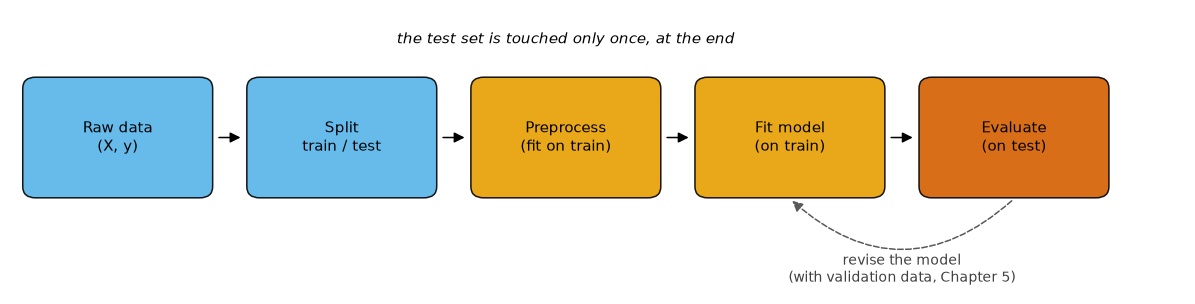

In [16]:
# Figure 1.5 — the standard supervised learning workflow
def figure_1_5():
    import matplotlib.pyplot as plt
    from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

    steps = ["Raw data\n(X, y)", "Split\ntrain / test", "Preprocess\n(fit on train)",
             "Fit model\n(on train)", "Evaluate\n(on test)"]
    fig, ax = plt.subplots(figsize=(11, 2.9))
    ax.set_xlim(0, 11)
    ax.set_ylim(0, 3)
    ax.axis("off")

    xs = [1.0, 3.1, 5.2, 7.3, 9.4]
    fills = [SKY, SKY, ORANGE, ORANGE, VERMILION]
    for x, label, fill in zip(xs, steps, fills):
        ax.add_patch(FancyBboxPatch((x - 0.85, 1.05), 1.7, 1.2, boxstyle="round,pad=0.04,rounding_size=0.12",
                                    facecolor=fill, edgecolor="black", linewidth=1.0, alpha=0.9))
        ax.text(x, 1.65, label, ha="center", va="center", fontsize=10)
    for a, b in zip(xs[:-1], xs[1:]):
        ax.add_patch(FancyArrowPatch((a + 0.92, 1.65), (b - 0.92, 1.65),
                                     arrowstyle="-|>", mutation_scale=14, color="black"))

    # feedback loop: use the results to improve the model (on validation data, see Chapter 5)
    ax.add_patch(FancyArrowPatch((9.4, 1.0), (7.3, 1.0), connectionstyle="arc3,rad=-0.45",
                                 arrowstyle="-|>", mutation_scale=14, color="0.35", linestyle="--"))
    ax.text(8.35, 0.12, "revise the model\n(with validation data, Chapter 5)", ha="center", fontsize=9, color="0.25")
    ax.text(5.2, 2.65, "the test set is touched only once, at the end", ha="center", fontsize=10, style="italic")
    fig.tight_layout()
    plt.show()

figure_1_5()

### The data: Breast Cancer Wisconsin (Diagnostic)

The data set (Street, Wolberg and Mangasarian, 1993) contains 569 digitized images of fine needle aspirates of breast masses. For each image, 30 numerical features describe the cell nuclei (radius, texture, area, and so on), and the label says whether the mass is *malignant* or *benign*. It is bundled with scikit-learn. This is a teaching example: the point is the *method*, not medical advice.

In [17]:
from sklearn.datasets import load_breast_cancer

bc = load_breast_cancer(as_frame=True)
X_bc, y_bc = bc.data, bc.target
print("X shape:", X_bc.shape)
print("classes:", dict(zip(bc.target_names.tolist(), np.bincount(y_bc).tolist())))
print("\nThe features live on very different scales:")
X_bc.describe().loc[["mean", "std"]].T.iloc[[0, 3, 4]].round(3)

X shape: (569, 30)
classes: {'malignant': 212, 'benign': 357}

The features live on very different scales:


,mean,std
mean radius,14.127,3.524
mean area,654.889,351.914
mean smoothness,0.096,0.014


Two observations before modeling. First, the classes are not perfectly balanced, so a trivial classifier that always answers "benign" already reaches a respectable accuracy: this is our **baseline** for classification, the analogue of the mean in regression. Second, *mean area* is of the order of hundreds, while *mean smoothness* is about 0.1: features on such different scales will be a problem for methods based on distances.

### The model: k-nearest neighbors

We use a method that needs no new mathematics, **k-nearest neighbors** (k-NN), studied in detail in Chapter 4. To classify a new sample, look at the $k$ training samples closest to it (in Euclidean distance) and take a majority vote of their labels. Here $k$ is a hyperparameter.

### Step 1 — split, step 2 — preprocess, step 3 — fit, step 4 — evaluate

In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

# 1) split: 75% training, 25% test; stratify keeps the class proportions in both parts
X_tr, X_te, y_tr, y_te = train_test_split(
    X_bc, y_bc, test_size=0.25, stratify=y_bc, random_state=SEED
)
print("training:", X_tr.shape, "| test:", X_te.shape)

# baseline: always predict the most frequent class of the training set
baseline = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
print(f"\nbaseline test accuracy (always the majority class): {baseline.score(X_te, y_te):.3f}")

# 2)+3) preprocess and fit. The pipeline standardizes each feature (mean 0, std 1),
#       estimating mean and std on the TRAINING set only, then fits k-NN.
knn_scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(X_tr, y_tr)

# the same model WITHOUT standardization, for comparison
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_tr, y_tr)

# 4) evaluate on the test set
print(f"k-NN (k=5), raw features   : train {knn_raw.score(X_tr, y_tr):.3f} | test {knn_raw.score(X_te, y_te):.3f}")
print(f"k-NN (k=5), standardized   : train {knn_scaled.score(X_tr, y_tr):.3f} | test {knn_scaled.score(X_te, y_te):.3f}")

training: (426, 30) | test: (143, 30)

baseline test accuracy (always the majority class): 0.629
k-NN (k=5), raw features   : train 0.946 | test 0.930
k-NN (k=5), standardized   : train 0.969 | test 0.979


Standardizing the features helps: once all features have comparable scales, no single one dominates the distance. Both models beat the baseline clearly.

The accuracy hides *which kind* of mistakes are made. The **confusion matrix** counts, for each true class (rows), how many samples received each predicted label (columns).

In [19]:
cm = confusion_matrix(y_te, knn_scaled.predict(X_te))
pd.DataFrame(cm,
             index=[f"true {n}" for n in bc.target_names],
             columns=[f"predicted {n}" for n in bc.target_names])

,predicted malignant,predicted benign
true malignant,50,3
true benign,0,90


In a medical setting the two kinds of error are not equally serious (a missed malignant tumor is worse than a false alarm), and accuracy alone does not capture this. Chapter 5 introduces metrics such as precision, recall, and the ROC curve.

### Memorization versus learning

What happens with $k = 1$, where each sample is classified by its single nearest training neighbor?

In [20]:
for k in [1, 5, 15]:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X_tr, y_tr)
    print(f"k = {k:>2}: training accuracy {model.score(X_tr, y_tr):.3f} | test accuracy {model.score(X_te, y_te):.3f}")

k =  1: training accuracy 1.000 | test accuracy 0.951
k =  5: training accuracy 0.969 | test accuracy 0.979
k = 15: training accuracy 0.969 | test accuracy 0.958


With $k = 1$ the training accuracy is exactly 1: every training sample is its own nearest neighbor, so the model has **memorized** the training set. A perfect training score says nothing about new patients. This is the same phenomenon as the high-degree polynomials of Section 1.7, in a different guise: here the flexibility knob is $k$ (small $k$ means a very flexible model).

:::{admonition} Pitfall
:class: warning
**Data leakage.** If you standardize the *whole* data set before splitting, the mean and the standard deviation are computed using test samples, and information from the test set leaks into training. Always fit preprocessing steps on the training data only, and apply them to the test data. Putting the steps in a `Pipeline`, as above, makes this automatic and is the habit we adopt throughout the book.
:::

:::{admonition} Pitfall
:class: warning
Accuracy is meaningful only compared with a baseline. On a data set where 95% of the samples belong to one class, a classifier that always answers that class has 95% accuracy and has learned nothing.
:::

## 1.9 Practical setup in a nutshell

This book is written to be **run**, not only read. Every chapter is a Jupyter notebook; you can execute it end to end on your computer and change anything you like. The complete, step-by-step instructions are in the [Setup Guide](ch01_setup_guide.md). Here is the summary.

**Run the book locally.**
1. Install Python (3.11 or newer) and create an isolated environment.
2. Install the packages listed in `requirements.txt`.
3. Open a chapter in JupyterLab and run its cells, or execute all the chapters with the command `python tools/book.py execute`.

**Build the book website locally, with all outputs already computed.** The notebooks are *executed on your computer*; their outputs (numbers, tables, figures) are stored inside the `.ipynb` files. Jupyter Book then turns the executed notebooks into static HTML pages **without running any code** (it does so unless you explicitly ask it to with `--execute`).

**Publish on GitHub Pages without any computation on GitHub.** The folder of static HTML pages produced locally is pushed to a dedicated branch (`gh-pages`) of the repository, and GitHub simply serves the files. No workflow that installs Python or runs notebooks is needed, so publishing a new chapter costs nothing and the published pages are exactly the ones you checked on your machine.

### Conventions used in the notebooks

- **Seeds.** Anything random uses a fixed seed (`SEED = 42`), so that your results match those printed here.
- **Self-contained figure cells.** The code of each figure lives in a function that re-loads its own data and imports what it needs, so it does not overwrite your variables and you can copy it into a script. The only things it takes from the setup cell are the colors and the seed.
- **Datasets** come from the libraries themselves (scikit-learn, and later seaborn and torchvision); the source of each data set is cited where it is first used.
- **Pipelines.** Preprocessing and model are combined with `make_pipeline`, to avoid data leakage.
- **Colors.** Figures use a color-blind-safe palette, and always add a second encoding (marker shape, line style, or direct labels).

## 1.10 Summary

- **Machine learning** builds programs from examples. Performance must be measured on *new* data.
- A supervised problem has five ingredients: **data** $(\mathbf{X}, \mathbf{y})$, a **model** family $f(\mathbf{x};\mathbf{w})$, a **loss** $\ell$, a **learning algorithm** (an optimization), and an **evaluation** protocol.
- Datasets are **matrices**: rows are samples (points in $\mathbb{R}^d$), columns are features. Distances and dot products have a meaning.
- **Empirical risk minimization**: choose the parameters with the smallest average training loss. Always compare with a **baseline** (the mean for regression, the majority class for classification).
- **Least squares** minimizes $\lVert \mathbf{y} - \mathbf{X}\mathbf{w}\rVert_2^2$. The solution satisfies the **normal equations** $\mathbf{X}^\top\mathbf{X}\mathbf{w} = \mathbf{X}^\top\mathbf{y}$ and is an **orthogonal projection** of $\mathbf{y}$ onto the column space of $\mathbf{X}$. Prefer `np.linalg.lstsq` to inverting $\mathbf{X}^\top\mathbf{X}$.
- The training error is optimistic. **Underfitting** (too rigid) and **overfitting** (too flexible) are detected by evaluating on a held-out **test set**. Never fit preprocessing on test data: use pipelines.

### Data sources

- *Iris*: R. A. Fisher, "The use of multiple measurements in taxonomic problems", *Annals of Eugenics* 7(2), 179–188 (1936). Bundled with scikit-learn.
- *Diabetes*: B. Efron, T. Hastie, I. Johnstone and R. Tibshirani, "Least Angle Regression", *Annals of Statistics* (with discussion), 407–499 (2004). Bundled with scikit-learn.
- *Breast Cancer Wisconsin (Diagnostic)*: W. N. Street, W. H. Wolberg and O. L. Mangasarian, "Nuclear feature extraction for breast tumor diagnosis", *IS&T/SPIE 1993 International Symposium on Electronic Imaging*, volume 1905, 861–870 (1993). Bundled with scikit-learn.

### Further reading

- T. M. Mitchell, *Machine Learning*, McGraw-Hill, 1997 (the definition of learning used in Section 1.2).
- T. Hastie, R. Tibshirani and J. Friedman, *The Elements of Statistical Learning*, 2nd ed., Springer, 2009 (Chapters 1–3 for the material of this chapter).
- G. Strang, *Introduction to Linear Algebra*, 5th ed., Wellesley-Cambridge Press, 2016 (projections and least squares).
- S. Shalev-Shwartz and S. Ben-David, *Understanding Machine Learning: From Theory to Algorithms*, Cambridge University Press, 2014 (for the theory previewed in Section 1.5, see Chapter 3 of this book).

## 1.11 Exercises

Difficulty: ★ warm-up, ★★ core, ★★★ challenge. Try each exercise before reading the hint; solutions and detailed outlines are in [Appendix C](../appendices/appendix_c_solutions.ipynb).

### Manual (analytical) exercises

**Exercise 1.1 ★ — Name the problem.** For each task, say whether it is supervised, unsupervised, or reinforcement learning, and, if supervised, whether it is regression or classification.
(a) Predicting tomorrow's electricity consumption of a city. (b) Grouping customers with similar purchase habits, without any predefined group. (c) Deciding whether an e-mail is spam. (d) Training a program to play a board game by playing against itself and observing wins and losses. (e) Reducing 1000 measurements per sample to 10 numbers that preserve most of the variation.

*Hint.* Ask: is there a target $y$ given for each example? If yes, is it a number or a category? If not, is there a reward signal?

**Exercise 1.2 ★ — Shapes.** A data set has $n = 200$ samples and $d = 5$ features. (a) What is the shape of $\mathbf{X}$? Of $\mathbf{y}$? (b) What is the shape of the design matrix with the intercept column? (c) What is the shape of $\mathbf{X}^\top\mathbf{X}$? (d) For $\mathbf{X} = \begin{pmatrix}1 & 2\\ 3 & 4 \\ 5 & 6\end{pmatrix}$ and $\mathbf{w} = (1, -1)^\top$, compute $\mathbf{X}\mathbf{w}$ and say what each entry represents.

*Hint.* In $\mathbf{X}\mathbf{w}$ each entry is the dot product of one row of $\mathbf{X}$ with $\mathbf{w}$.

**Exercise 1.3 ★★ — Least squares by hand.** Fit a line $y = w_0 + w_1 x$ by least squares to the points $(0, 2)$, $(1, 2)$, $(2, 5)$. (a) Write $\mathbf{X}$ and $\mathbf{y}$, form the normal equations, and solve them. (b) Compute the residuals and verify that $\mathbf{X}^\top\mathbf{r} = \mathbf{0}$. (c) Compute the MSE and $R^2$.

*Hint.* Follow Worked example 1.2: here $\mathbf{X}^\top\mathbf{X}$ is the same matrix, only $\mathbf{y}$ changes.

**Exercise 1.4 ★★ — Derive it yourself.** Consider the model with a single feature and no intercept, $f(x) = w x$, and the loss $L(w) = \sum_{i=1}^n (y_i - w x_i)^2$. (a) Find $\hat{w}$ by setting $L'(w) = 0$. (b) Show that your formula is the special case $d = 1$ of $\hat{\mathbf{w}} = (\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top\mathbf{y}$. (c) Show that $L''(w) > 0$, so that $\hat w$ is a minimum, provided that not all $x_i$ are zero.

*Hint.* Expand the square, differentiate term by term, and recognize $\sum_i x_i y_i$ and $\sum_i x_i^2$ as dot products.

**Exercise 1.5 ★★★ — Which loss, which constant?** Let $y_1 \le y_2 \le \dots \le y_n$ with $n$ odd. (a) Show that the constant $c$ minimizing $\sum_i (y_i - c)^2$ is the mean. (b) Show that the constant minimizing $\sum_i \lvert y_i - c\rvert$ is the **median** $y_{(n+1)/2}$. (c) Add a huge outlier to the data (for instance replace $y_n$ with $10^6$): what happens to the two optimal constants? What does this suggest about the choice of loss?

*Hint for (b).* The function $c \mapsto \sum_i \lvert y_i - c\rvert$ is piecewise linear. Its slope at a point $c$ that is not a data point is (number of $y_i < c$) $-$ (number of $y_i > c$). Where does the slope change sign?

### Python (computational) exercises

**Exercise 1.6 ★ — Meet a new data set.** Load the **Wine** data set with `sklearn.datasets.load_wine(as_frame=True)`. Report: the shape of $\mathbf{X}$, the number of classes and the number of samples in each, the names of the first five features, and the mean and standard deviation of each feature. Which feature has the largest scale? What does that suggest for a distance-based method?

*Hint.* `np.bincount`, `DataFrame.describe()`.

**Exercise 1.7 ★★ — A line on Iris.** On the Iris data, predict *petal width* from *petal length* with a line. (a) Compute $\hat{\mathbf{w}}$ with the normal equations, with `np.linalg.lstsq`, and with `LinearRegression`; check that they agree. (b) Compute the MSE, the baseline MSE, and $R^2$. (c) Plot the data and the line.

*Hint.* Build the design matrix with `np.column_stack([np.ones(n), x])`, as in Section 1.6.

**Exercise 1.8 ★★ — Does scaling matter?** On the Breast Cancer data, with the same split as in Section 1.8, compute the test accuracy of k-NN for $k = 1, 2, \dots, 15$, with and without standardization. Plot the two curves. Then repeat the whole experiment for ten different values of `random_state` in the split and plot the average test accuracy with and without scaling. Is the conclusion stable?

*Hint.* Loop over $k$ and over seeds; keep results in a NumPy array of shape `(n_seeds, n_k)` and average over the first axis.

**Exercise 1.9 ★★★ — Your own overfitting experiment.** Repeat the experiment of Figure 1.4 with a different feature of the Diabetes data set (for example `bp` or `s5`) and with training sets of sizes 30, 100, and 300. For each size, find the degree with the smallest median test error over 100 random splits. How does the best degree depend on the training-set size? Explain the trend in a few sentences.

*Hint.* Reuse the function `fit_and_score` of Figure 1.4. Median errors are more robust than means because a few splits give enormous errors.

**Exercise 1.10 ★★★ — When $\mathbf{X}^\top\mathbf{X}$ is singular.** On the Diabetes data with the `bmi` feature, add a *duplicate* column, equal to `bmi` (so that the two columns are linearly dependent). (a) Compute the rank of the design matrix and the condition number of $\mathbf{X}^\top\mathbf{X}$ (`np.linalg.matrix_rank`, `np.linalg.cond`). (b) What happens if you call `np.linalg.solve` on the normal equations? (c) What does `np.linalg.lstsq` return? Does the *prediction* $\hat{\mathbf{y}}$ change compared with the model that uses `bmi` once? (d) Explain what you see in terms of the column space.

*Hint.* There are infinitely many weight vectors giving the same projection. Which one does `lstsq` pick? (Compare the norms of two candidates, for instance $(w, 0)$ and $(w/2, w/2)$.)

## What comes next

In **Chapter 2** we review the Python and mathematical tools that the rest of the book relies on: NumPy and pandas in depth, plotting, and the probability needed to talk about data. In **Chapter 3** we turn the informal ideas of Sections 1.5 and 1.7 (empirical risk, expected risk, overfitting) into a precise theory.